# Step 5: Clustering - Finding Groups of Customers

**Goal (unsupervised learning):** group customers by **how much they buy, how profitable they are, and what delivery experience they get**, without telling the algorithm what the groups should be. Then give each group a business meaning.

### How this differs from the usual approach
Most public notebooks on this dataset do **RFM scoring**: split recency, frequency and money into quartiles and add up the scores. I use a different approach:
- **Real clustering algorithms:** **K-Means**, checked against **Hierarchical clustering (Ward)**
- **Delivery and profit features**, not only spending: late share, premium-shipping share, profit margin
- **Choosing the number of clusters with evidence** (elbow method + silhouette score)
- **Data-quality check first:** I found a problem with customer IDs that would distort any customer analysis

### Why customers and not countries?
My proposal said "customers or regions". I check both quickly in section 3 and explain why customers are the better choice.

## 1. Setup

In [1]:
import sys, os, subprocess
IN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data (same loader as Steps 2–4)

In [2]:
def find_processed_dir():
    candidates = ["/content/drive/MyDrive/dataco-final-project/processed",
                  "/content/dataco-final-project/processed",
                  os.path.join("..", "data", "processed")]
    if IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
    for c in candidates:
        if os.path.exists(os.path.join(c, "orders_clean.parquet")):
            return c
    return None

def rebuild_orders_from_raw():
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    data_dir = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
    raw = pd.read_csv(os.path.join(data_dir, "DataCoSupplyChainDataset.csv"), encoding="latin-1")
    raw["order_date"] = pd.to_datetime(raw["order date (DateOrders)"])
    orders = (raw.groupby("Order Id")
                 .agg(order_date=("order_date", "first"),
                      customer_segment=("Customer Segment", "first"), market=("Market", "first"),
                      order_region=("Order Region", "first"), order_country=("Order Country", "first"),
                      shipping_mode=("Shipping Mode", "first"), payment_type=("Type", "first"),
                      days_scheduled=("Days for shipment (scheduled)", "first"),
                      days_real=("Days for shipping (real)", "first"),
                      late=("Late_delivery_risk", "first"),
                      delivery_status=("Delivery Status", "first"),
                      n_items=("Order Item Id", "count"), total_quantity=("Order Item Quantity", "sum"),
                      gross_sales=("Sales", "sum"), total_discount=("Order Item Discount", "sum"),
                      n_categories=("Category Name", "nunique"))
                 .reset_index().rename(columns={"Order Id": "order_id"}))
    orders["is_canceled"] = orders["delivery_status"].eq("Shipping canceled")
    orders["avg_discount_rate"] = orders["total_discount"] / orders["gross_sales"]
    return orders


proc = find_processed_dir()
if proc:
    orders = pd.read_parquet(os.path.join(proc, "orders_clean.parquet"))
    print("Loaded cleaned orders from:", proc)
else:
    print("Cleaned files not found - rebuilding from raw data (about 1 minute)...")
    orders = rebuild_orders_from_raw()
orders = orders.sort_values("order_date").reset_index(drop=True)
if "profit" not in orders.columns:   # the raw rebuild in Step 3 doesn't include profit; add it back
    print("Note: profit columns missing - please run Step 1 first and save to Drive for this notebook.")
orders["premium_shipping"] = orders["shipping_mode"].isin(["First Class", "Second Class", "Same Day"]).astype(int)
print(f"Orders: {len(orders):,}   Customers: {orders['customer_id'].nunique():,}")

Loaded cleaned orders from: ..\data\processed
Orders: 65,752   Customers: 20,652


## 3. Countries or customers?
If country groups are real, the late rate should differ between countries **more than random chance would explain**.
I compare the actual spread with the spread we'd expect from pure chance, given each country's number of orders.

In [3]:
shipped = orders[~orders["is_canceled"]]
by_country = shipped.groupby("order_country").agg(orders=("order_id", "count"), late_rate=("late", "mean"))
by_country = by_country[by_country["orders"] >= 100]
p = shipped["late"].mean()
expected_sd = np.sqrt((p * (1 - p) / by_country["orders"]).mean())
print(f"Countries with 100+ orders: {len(by_country)}")
print(f"Late rate ranges from {by_country['late_rate'].min():.1%} to {by_country['late_rate'].max():.1%}")
print(f"Actual spread (std) between countries:      {by_country['late_rate'].std():.3f}")
print(f"Spread expected from random chance alone:    {expected_sd:.3f}")

Countries with 100+ orders: 62
Late rate ranges from 49.1% to 63.1%
Actual spread (std) between countries:      0.029
Spread expected from random chance alone:    0.027


**What I learned:** the differences between countries are about the **size you'd expect from chance**. That fits Step 2, where geography had no effect on delays.
Clustering countries would just group random noise. **Customers** show much more real variation (how often they buy, how much they spend, which shipping they choose), so I cluster customers.

## 4. Data-quality check: customer IDs
Before analysing customers, I check whether customer IDs are reliable over time.

Orders from Oct 2017 onward: 8,403
  ...placed by customers who had ordered before: 1.0%
  ...customers with more than one order in this period: 0


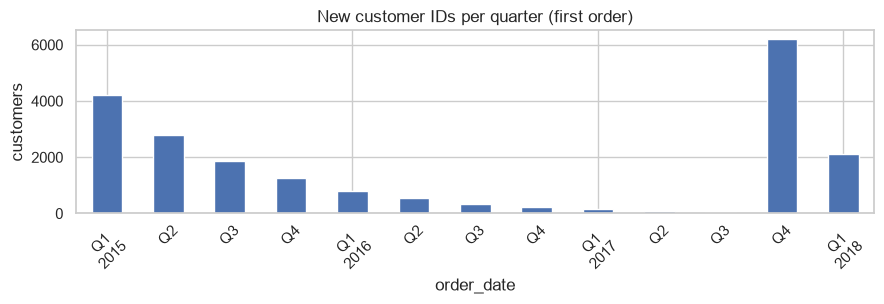

In [4]:
first_seen = orders.groupby("customer_id")["order_date"].min()
recent = orders[orders["order_date"] >= "2017-10-01"]
print(f"Orders from Oct 2017 onward: {len(recent):,}")
print(f"  ...placed by customers who had ordered before: {(recent['customer_id'].map(first_seen) < '2017-10-01').mean():.1%}")
print(f"  ...customers with more than one order in this period: {(recent.groupby('customer_id').size() > 1).sum()}")

new_customers = first_seen.dt.to_period("Q").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
new_customers.plot.bar(ax=ax, color="#4C72B0", rot=45)
ax.set_title("New customer IDs per quarter (first order)"); ax.set_ylabel("customers")
plt.tight_layout(); plt.show()

**What I found:** from **October 2017**, almost every order comes from a **new customer ID that never orders again**. In earlier quarters, new customers become rare as the customer base matures.
This doesn't look like real behaviour. It's more likely the system started giving a new ID to each order.
**Decision:** I only use orders **before 1 Oct 2017** for customer clustering. Otherwise thousands of fake "one-time customers" would form their own cluster.

## 5. Build customer features
For each customer (orders before Oct 2017, shipped orders only):

| Feature | Meaning | Group |
|---|---|---|
| `n_orders` | how many orders | value |
| `total_spend` | total net sales | value |
| `avg_margin` | average profit margin of their orders | profit |
| `late_share` | share of their orders that arrived late | delivery |
| `premium_share` | share of orders using First/Second/Same Day shipping | delivery |
| `days_since_last` | days since their last order (on 1 Oct 2017) | activity |

`n_orders` and `total_spend` are very skewed (a few customers buy a lot), so I use their log. Then I **standardize** all features so each one counts equally.

In [5]:
snapshot = pd.Timestamp("2017-10-01")
base = orders[(orders["order_date"] < snapshot) & (~orders["is_canceled"])]

customers = base.groupby("customer_id").agg(
    n_orders=("order_id", "count"),
    total_spend=("net_sales", "sum"),
    avg_order_value=("net_sales", "mean"),
    total_profit=("profit", "sum"),
    avg_margin=("profit_margin", "mean"),
    late_share=("late", "mean"),
    premium_share=("premium_shipping", "mean"),
    last_order=("order_date", "max"),
    segment=("customer_segment", "first"),
)
customers["days_since_last"] = (snapshot - customers["last_order"]).dt.days

features = ["n_orders", "total_spend", "avg_margin", "late_share", "premium_share", "days_since_last"]
X = customers[features].copy()
X["n_orders"] = np.log1p(X["n_orders"])
X["total_spend"] = np.log1p(X["total_spend"])
X_scaled = StandardScaler().fit_transform(X)

print(f"Customers used for clustering: {len(customers):,}")
customers[features].describe().round(2)

Customers used for clustering: 12,296


,n_orders,total_spend,avg_margin,late_share,premium_share,days_since_last
count,12296.00,12296.00,12296.00,12296.00,12296.00,12296.00
mean,4.46,2396.21,0.12,0.57,0.40,213.64
std,2.06,1280.96,0.20,0.27,0.27,196.60
min,1.00,24.25,-1.80,0.00,0.00,0.00
25%,3.00,1453.54,0.04,0.40,0.25,64.00
50%,4.00,2235.24,0.16,0.58,0.40,155.00
75%,6.00,3172.74,0.25,0.75,0.56,304.00
max,14.00,9436.61,0.50,1.00,1.00,1002.00


## 6. How many clusters? (elbow method + silhouette score)
- **Elbow:** the within-cluster distance (inertia) always drops as k grows; I look for where the drop slows down.
- **Silhouette score:** how well each customer fits its own cluster compared with the nearest other cluster (−1 to 1; higher is better).

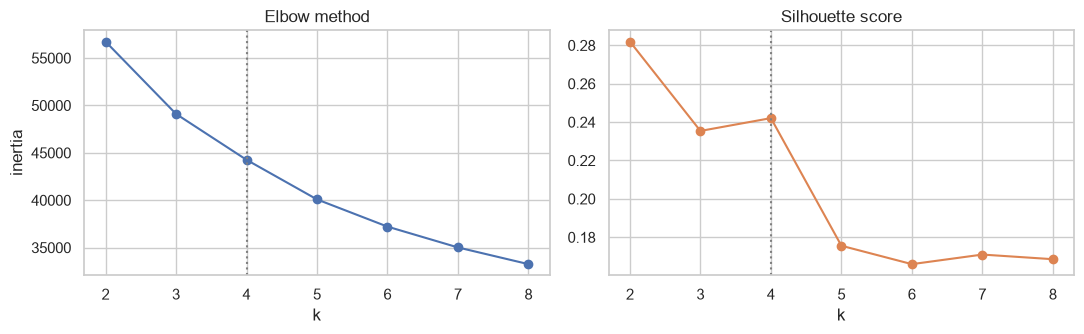

,k,inertia,silhouette
0,2,56735.0,0.282
1,3,49105.0,0.235
2,4,44263.0,0.242
3,5,40084.0,0.176
4,6,37214.0,0.166
5,7,35017.0,0.171
6,8,33255.0,0.169


In [6]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_, sample_size=8000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(list(ks), inertia, marker="o"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[1].plot(list(ks), silhouette, marker="o", color="#DD8452"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
for ax in axes: ax.axvline(4, color="grey", ls=":")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "silhouette": np.round(silhouette, 3)})

**My choice: k = 4.**
- k = 2 has the highest silhouette, but two groups are too broad to act on.
- The elbow bends around k = 3–4, and k = 4 keeps almost the same silhouette as k = 3.
- From k = 5 the silhouette drops clearly, so extra clusters would be splitting real groups.

A silhouette of about 0.23 means the clusters **overlap somewhat**. Customer behaviour is a continuum, not neat boxes. That's normal for real customer data, and I mention it honestly.

## 7. K-Means with k = 4

In [7]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
customers["cluster"] = kmeans.labels_

profile = customers.groupby("cluster").agg(
    customers=("n_orders", "size"),
    n_orders=("n_orders", "mean"),
    total_spend=("total_spend", "mean"),
    avg_margin=("avg_margin", "mean"),
    total_profit=("total_profit", "mean"),
    late_share=("late_share", "mean"),
    premium_share=("premium_share", "mean"),
    days_since_last=("days_since_last", "mean"),
)

# Give each cluster a business name based on its profile (works even if cluster numbers change between runs)
names, remaining = {}, list(profile.index)
c = profile.loc[remaining, "avg_margin"].idxmin();    names[c] = "Loss-making customers";       remaining.remove(c)
c = profile.loc[remaining, "n_orders"].idxmax();      names[c] = "Loyal high-value";            remaining.remove(c)
c = profile.loc[remaining, "premium_share"].idxmax(); names[c] = "Premium shippers, often late"; remaining.remove(c)
names[remaining[0]] = "Occasional standard shippers"

customers["cluster_name"] = customers["cluster"].map(names)
profile.index = profile.index.map(names)
profile["share_of_customers"] = profile["customers"] / profile["customers"].sum()
profile.round(2)

,customers,n_orders,total_spend,avg_margin,total_profit,late_share,premium_share,days_since_last,share_of_customers
cluster,,,,,,,,,
Occasional standard shippers,1976,2.86,1444.29,0.18,237.82,0.24,0.11,315.59,0.16
"Premium shippers, often late",2605,2.61,1305.76,0.20,248.64,0.78,0.61,342.12,0.21
Loyal high-value,6464,5.84,3220.12,0.15,444.96,0.58,0.40,128.75,0.53
Loss-making customers,1251,3.74,1913.24,-0.29,-370.85,0.62,0.41,223.71,0.10


### Cluster profiles side by side

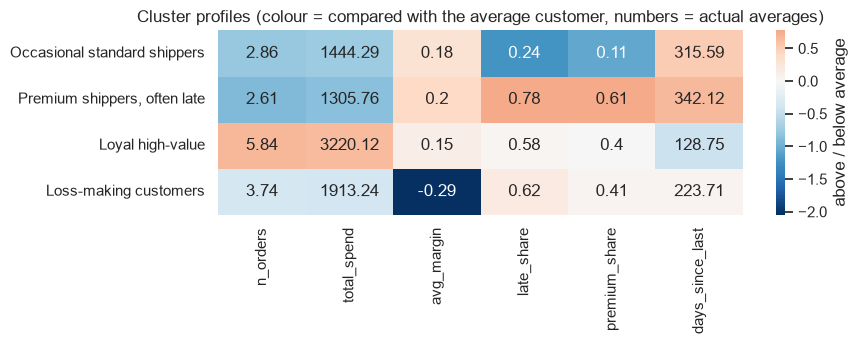

In [8]:
z = (profile[features] - customers[features].mean()) / customers[features].std()
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.heatmap(z, annot=profile[features].round(2), fmt="", cmap="RdBu_r", center=0, cbar_kws={"label": "above / below average"}, ax=ax)
ax.set_title("Cluster profiles (colour = compared with the average customer, numbers = actual averages)")
ax.set_ylabel("")
plt.tight_layout(); plt.show()

### Visualizing the clusters in 2-D (PCA)

The 2 PCA components explain 60% of the variation


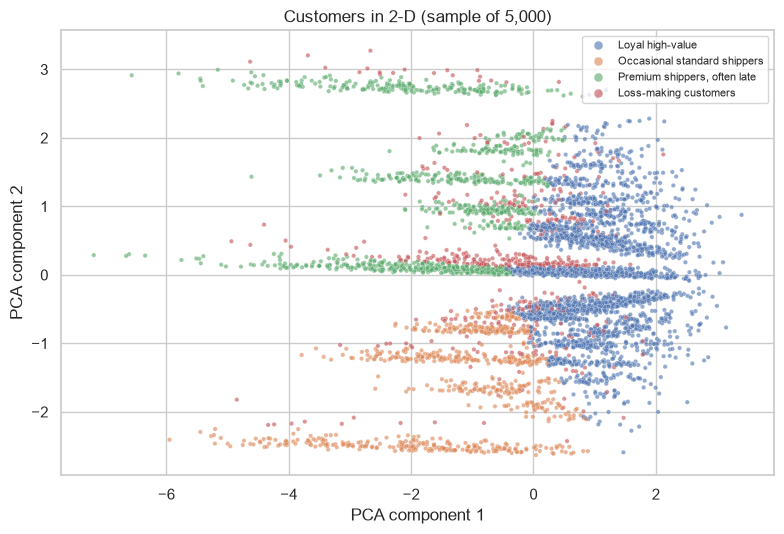

,PC1,PC2
n_orders,0.63,-0.03
total_spend,0.62,-0.02
avg_margin,-0.01,-0.06
late_share,0.03,0.71
premium_share,0.02,0.71
days_since_last,-0.47,0.01


In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
print(f"The 2 PCA components explain {pca.explained_variance_ratio_.sum():.0%} of the variation")

fig, ax = plt.subplots(figsize=(8, 5.5))
sample = np.random.RandomState(RANDOM_STATE).choice(len(coords), 5000, replace=False)
sns.scatterplot(x=coords[sample, 0], y=coords[sample, 1], hue=customers["cluster_name"].values[sample],
                s=10, alpha=0.6, ax=ax)
ax.set_xlabel("PCA component 1"); ax.set_ylabel("PCA component 2")
ax.set_title("Customers in 2-D (sample of 5,000)"); ax.legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()

pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(2)

## 8. Checking with a second method: Hierarchical clustering (Ward)
If a completely different algorithm finds similar groups, the clusters are more trustworthy.
Hierarchical clustering is slow on 12,000 customers, so I use a random sample of 3,000.

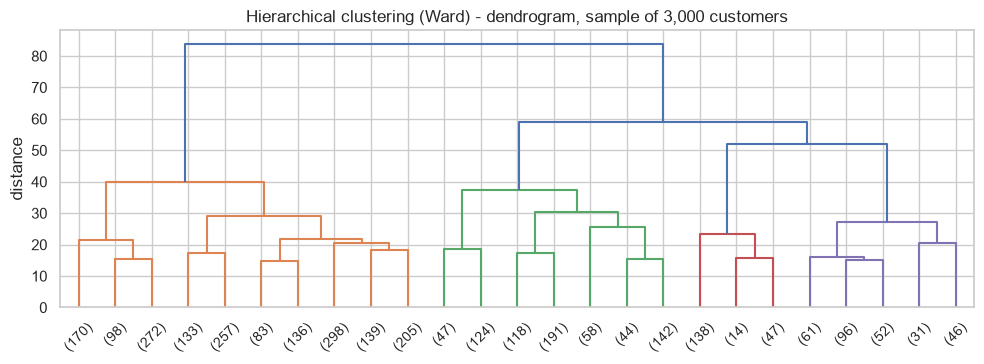

Agreement between K-Means and Ward (Adjusted Rand Index): 0.60   (0 = random, 1 = identical)


Ward cluster,0,1,2,3
K-Means,,,,
Loss-making customers,64,6,34,190
Loyal high-value,1531,0,67,3
Occasional standard shippers,86,0,402,2
"Premium shippers, often late",110,280,221,4


In [10]:
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), 3000, replace=False)
Z = linkage(X_scaled[idx], method="ward")

fig, ax = plt.subplots(figsize=(10, 3.8))
dendrogram(Z, truncate_mode="lastp", p=25, ax=ax, color_threshold=Z[-(K - 1), 2])
ax.set_title("Hierarchical clustering (Ward) - dendrogram, sample of 3,000 customers")
ax.set_ylabel("distance")
plt.tight_layout(); plt.show()

ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X_scaled[idx])
ari = adjusted_rand_score(kmeans.labels_[idx], ward.labels_)
print(f"Agreement between K-Means and Ward (Adjusted Rand Index): {ari:.2f}   (0 = random, 1 = identical)")
pd.crosstab(customers["cluster_name"].values[idx], ward.labels_, rownames=["K-Means"], colnames=["Ward cluster"])

## 9. Does the customer segment label explain the clusters?
The dataset has a `Customer Segment` column (Consumer / Corporate / Home Office). Do my clusters just repeat it?

In [11]:
seg_mix = pd.crosstab(customers["cluster_name"], customers["segment"], normalize="index").round(2)
display(seg_mix)
chi2, p_value, _, _ = chi2_contingency(pd.crosstab(customers["cluster_name"], customers["segment"]))
print(f"Chi-square p-value: {p_value:.3f}")

segment,Consumer,Corporate,Home Office
cluster_name,,,
Loss-making customers,0.53,0.28,0.18
Loyal high-value,0.51,0.31,0.18
Occasional standard shippers,0.51,0.30,0.18
"Premium shippers, often late",0.53,0.29,0.18


Chi-square p-value: 0.591


## 10. Extra question: does a late first order stop customers coming back?
If late delivery drove customers away, that would be the strongest business reason to fix it.
I take customers whose **first order** was placed before April 2017 and shipped, then check whether they ordered again before October 2017.

In [12]:
first_orders = orders.groupby("customer_id").first()   # orders are sorted by date
first_orders = first_orders[(first_orders["order_date"] < "2017-04-01") & (~first_orders["is_canceled"])]
n_before_snapshot = orders[orders["order_date"] < snapshot].groupby("customer_id").size()
first_orders["came_back"] = (n_before_snapshot.reindex(first_orders.index) > 1).astype(int)

ret = first_orders.groupby(first_orders["late"].map({0: "first order on time", 1: "first order late"}))["came_back"].agg(["mean", "count"])
ret.columns = ["return_rate", "customers"]
display(ret.round(3))
chi2, p_value, _, _ = chi2_contingency(pd.crosstab(first_orders["late"], first_orders["came_back"]))
print(f"Chi-square p-value: {p_value:.3f}")

,return_rate,customers
late,,
first order late,0.964,6632
first order on time,0.961,5004


Chi-square p-value: 0.471


## 11. Summary of Step 5

In [13]:
summary = profile[["customers", "share_of_customers", "n_orders", "total_spend", "avg_margin",
                   "total_profit", "late_share", "premium_share", "days_since_last"]].copy()
summary["share_of_total_profit"] = (customers.groupby("cluster_name")["total_profit"].sum()
                                    / customers["total_profit"].sum()).reindex(summary.index)
summary.round(2)

,customers,share_of_customers,n_orders,total_spend,avg_margin,total_profit,late_share,premium_share,days_since_last,share_of_total_profit
cluster,,,,,,,,,,
Occasional standard shippers,1976,0.16,2.86,1444.29,0.18,237.82,0.24,0.11,315.59,0.13
"Premium shippers, often late",2605,0.21,2.61,1305.76,0.20,248.64,0.78,0.61,342.12,0.18
Loyal high-value,6464,0.53,5.84,3220.12,0.15,444.96,0.58,0.40,128.75,0.81
Loss-making customers,1251,0.10,3.74,1913.24,-0.29,-370.85,0.62,0.41,223.71,-0.13
